# TP 2 — Apprentissage Profond avec TensorFlow / Keras

**Module :** Technologies IA — **Prof :** Youness IDRISSI KHAMLICHI
**Filière :** Ingénierie Logicielle et Intelligence Artificielle — ILIA2, ENSA Fès
**Étudiante :** Chaimae Hammach

Ce notebook contient le code complet des deux exercices, les sorties obtenues, les réponses à toutes les questions et une analyse personnelle par exercice.

| Exercice | Dataset | Modèles |
|---|---|---|
| 1 | MNIST (chiffres 0–9) | Réseau dense (MLP) |
| 2 | Fashion-MNIST (vêtements) | ANN, comparaison d'activations, CNN, CNN + data augmentation |

---
# Exercice 1 — Reconnaissance de chiffres manuscrits (MNIST)

## 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import json

tf.keras.utils.set_random_seed(42)   # reproductibilité (numpy, python, TF)
RES = {}                              # on y range les métriques pour le récapitulatif final

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Réponses

**1. Différence entre TensorFlow et Keras ?**
TensorFlow est le **moteur** : il manipule les tenseurs, calcule automatiquement les gradients (différentiation automatique) et exécute les calculs sur CPU/GPU/TPU. Keras est l'**interface haut niveau** intégrée à TensorFlow (`tf.keras`) : on décrit le réseau couche par couche (`Sequential`, `Dense`…) et Keras se charge de la boucle d'entraînement (`fit`), de l'évaluation et de la prédiction.
*Analogie :* TensorFlow est le moteur d'une voiture, Keras est le volant et les pédales. On peut conduire sans connaître la mécanique, mais c'est le moteur qui fait avancer.

**2. À quoi sert la couche `Flatten` ?**
Une couche `Dense` attend un **vecteur** en entrée. `Flatten` « déplie » l'image 28×28 en un vecteur de 28 × 28 = **784** valeurs, ligne par ligne. Elle n'a **aucun paramètre** : elle ne fait que changer la forme des données. Inconvénient : on perd l'information de voisinage entre pixels (deux pixels voisins verticalement se retrouvent à 28 positions d'écart), ce que le CNN corrigera dans l'exercice 2.

**3. Version de TensorFlow installée :** voir la sortie de la cellule ci-dessus (TensorFlow 2.21.0).

**4. À quoi servent `Sequential` et `Dense` ?**
- `Sequential` est un conteneur qui empile des couches **dans l'ordre** : la sortie de chaque couche est l'entrée de la suivante. Adapté aux réseaux sans branches.
- `Dense` est une couche **entièrement connectée** : chaque neurone est relié à toutes les sorties de la couche précédente et calcule $y = f(W x + b)$, avec $W$ les poids, $b$ le biais et $f$ la fonction d'activation.

## 2. Chargement et préparation du dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Avant normalisation :", x_train.dtype, "| min =", x_train.min(), "| max =", x_train.max())

# Normalisation
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Après normalisation :", x_train.dtype, "| min =", x_train.min(), "| max =", x_train.max())
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape :", x_test.shape)
print("Répartition des classes (train) :", np.bincount(y_train))

Avant normalisation : uint8 | min = 0 | max = 255


Après normalisation : float64 | min = 0.0 | max = 1.0
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape : (10000, 28, 28)
Répartition des classes (train) : [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


### Réponses

**1. Pourquoi normalise-t-on les pixels ?**
Les pixels bruts vont de 0 à 255. Avec des entrées aussi grandes, les sommes pondérées $W x$ deviennent grandes, les gradients aussi, et l'optimiseur fait des pas déséquilibrés : l'apprentissage est instable ou lent. En ramenant tout entre 0 et 1, toutes les entrées sont sur la même échelle que les poids initiaux (qui sont petits), donc la descente de gradient converge plus vite et plus sûrement.

**2. Taille et type d'une image :** une image fait **28 × 28 pixels**, en niveaux de gris (1 seul canal). Les données brutes sont des entiers non signés `uint8` (0–255) ; après la division par 255.0 elles deviennent des `float64` entre 0 et 1.

**3. Nombre d'exemples d'entraînement :** **60 000** images (et 10 000 pour le test, soit 70 000 au total). Les 10 classes sont à peu près équilibrées (entre ~5 400 et ~6 700 images par chiffre), donc l'accuracy est une métrique pertinente ici.

## 3. Visualisation d'échantillons

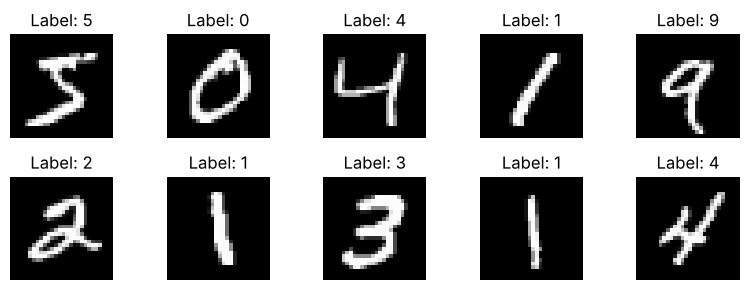

In [3]:
plt.figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### À faire

- **Chiffres affichés :** 5, 0, 4, 1, 9, 2, 1, 3, 1, 4.
- **Vérification :** chaque image correspond bien à son label. On remarque déjà la variabilité de l'écriture (le premier « 5 » est assez penché, le « 4 » n'est pas fermé), c'est précisément ce que le réseau doit apprendre à tolérer.

### Réponses

**1. Commande pour modifier le nombre d'images affichées :** c'est `range(10)` qui fixe le nombre d'images, et `plt.subplot(2, 5, i+1)` qui fixe la grille (2 lignes × 5 colonnes). Pour afficher 15 images : `range(15)` avec `plt.subplot(3, 5, i+1)`. Il faut toujours que lignes × colonnes ≥ nombre d'images.

**2. Que représente `cmap='gray'` ?** C'est la **palette de couleurs** (colormap). L'image n'a qu'un canal, donc matplotlib doit décider quelle couleur associer à chaque valeur : `gray` affiche 0 en noir et 1 en blanc. Sans cet argument, matplotlib utilise `viridis` par défaut (violet → jaune), ce qui donne des chiffres en fausses couleurs.

**3. Utilité de cette étape :** c'est un **contrôle qualité** avant d'entraîner : vérifier que les images sont lisibles, que les labels correspondent (un décalage d'indice entre images et labels rendrait l'apprentissage impossible) et que le prétraitement n'a rien cassé. Ça permet aussi de se faire une idée de la difficulté du problème.

## 4. Construction du modèle de réseau de neurones

In [4]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Réponses

**1. Nombre de paramètres :** chaque neurone d'une couche `Dense` a **un poids par entrée + un biais**.

| Couche | Calcul | Paramètres |
|---|---|---|
| Flatten | aucun poids | 0 |
| Dense(128) | 784 × 128 + 128 | 100 480 |
| Dense(10) | 128 × 10 + 10 | 1 290 |
| **Total** | | **101 770** |

C'est exactement ce qu'affiche `model.summary()`. On voit que 98,7 % des paramètres sont dans la première couche : c'est le coût de connecter chaque pixel à chaque neurone.

**2. Activation de la couche de sortie : `softmax`.**
Le problème a 10 classes exclusives. Softmax transforme les 10 scores bruts $z_i$ en **probabilités** : $\text{softmax}(z_i) = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$. Chaque sortie est entre 0 et 1 et la somme vaut 1. On lit donc directement « le modèle est sûr à 97 % que c'est un 7 », et la classe prédite est `argmax`.

**3. Différence entre ReLU et Softmax :**

| | ReLU | Softmax |
|---|---|---|
| Formule | $\max(0, x)$ | $e^{z_i} / \sum_j e^{z_j}$ |
| Agit sur | chaque neurone **indépendamment** | **tout le vecteur** à la fois (les sorties dépendent les unes des autres) |
| Sortie | $[0, +\infty[$ | $]0, 1[$, somme = 1 |
| Rôle | couches cachées : apporter la non-linéarité | couche de sortie : produire une distribution de probabilité |

## 5. Compilation du modèle

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Réponses

**1. Qu'est-ce qu'un optimiseur ?**
C'est l'algorithme qui **met à jour les poids** à partir des gradients calculés par la rétropropagation. La version de base (SGD) fait $w \leftarrow w - \eta \cdot \dfrac{\partial L}{\partial w}$ : on descend la pente de la perte avec un pas $\eta$ (le learning rate). **Adam** améliore ça en adaptant le pas pour chaque poids (grand pas pour les poids peu mis à jour, petit pas pour ceux qui oscillent) et en ajoutant de l'inertie (momentum).
*Analogie :* la perte est une montagne dans le brouillard, on veut atteindre la vallée. Le gradient indique la pente sous nos pieds, l'optimiseur décide de la taille et de la direction de chaque pas.

**2. Pourquoi une fonction de perte ?**
Parce qu'il faut un **nombre unique et dérivable** qui mesure l'erreur, pour pouvoir calculer son gradient par rapport à chaque poids. Sans perte, l'optimiseur ne saurait pas dans quelle direction corriger. Ici, la cross-entropy vaut $-\log(p_{\text{vraie classe}})$ : si le modèle donne 0,9 à la bonne classe la perte est 0,105 ; s'il donne 0,1 la perte monte à 2,3. Elle punit fortement les erreurs commises avec confiance.

**3. Que se passe-t-il si on change la fonction de perte ?**
On change **ce que le modèle cherche à optimiser**, donc ce qu'il apprend.
- `categorical_crossentropy` : même calcul, mais attend des labels **one-hot** (`[0,0,0,1,0,…]`). Avec nos labels entiers (`3`), Keras lève une erreur de forme. La version `sparse_` évite justement de faire l'encodage one-hot.
- `mse` (erreur quadratique) : ça tourne, mais c'est mal adapté à des probabilités : les gradients deviennent très faibles quand le softmax sature, et l'apprentissage est plus lent.
- `binary_crossentropy` : conçue pour 2 classes, elle donne des résultats incohérents sur 10 classes.

**4. Conséquence d'un mauvais choix d'optimiseur :**
Un learning rate trop grand fait **diverger** ou osciller la perte (on saute par-dessus la vallée) ; trop petit, l'entraînement est **extrêmement lent** ou se bloque dans un plateau. SGD sans momentum converge aussi plus lentement qu'Adam sur ce type de problème. Au final : soit un modèle moins précis pour le même nombre d'époques, soit pas de convergence du tout.

**5. Différence entre `loss` et `metrics` :**
- La **loss** est ce que l'optimiseur **minimise** : elle doit être dérivable et sert au calcul des gradients.
- Les **metrics** servent uniquement à **surveiller** les performances pour l'humain ; elles n'influencent pas l'entraînement. L'accuracy n'est d'ailleurs pas dérivable (elle passe de 0 à 1 en escalier), c'est pour ça qu'on ne peut pas l'optimiser directement.

## 6. Entraînement du modèle

> **Modification par rapport à l'énoncé :** le code d'origine utilise `validation_data=(x_test, y_test)`, puis évalue de nouveau sur `x_test` à l'étape 7. Le jeu de test sert alors deux fois, et il n'est plus vraiment « jamais vu » (on regarde ses scores pendant l'entraînement pour décider quoi faire). On utilise donc `validation_split=0.2` : Keras garde les **derniers 20 % du train** (12 000 images) comme validation, et le test reste intact jusqu'à l'évaluation finale.

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=2
)

Epoch 1/5


1500/1500 - 4s - 3ms/step - accuracy: 0.9188 - loss: 0.2834 - val_accuracy: 0.9552 - val_loss: 0.1571


Epoch 2/5


1500/1500 - 4s - 2ms/step - accuracy: 0.9639 - loss: 0.1246 - val_accuracy: 0.9655 - val_loss: 0.1173


Epoch 3/5


1500/1500 - 4s - 2ms/step - accuracy: 0.9750 - loss: 0.0855 - val_accuracy: 0.9708 - val_loss: 0.1025


Epoch 4/5


1500/1500 - 4s - 2ms/step - accuracy: 0.9819 - loss: 0.0630 - val_accuracy: 0.9727 - val_loss: 0.0970


Epoch 5/5


1500/1500 - 4s - 3ms/step - accuracy: 0.9869 - loss: 0.0476 - val_accuracy: 0.9736 - val_loss: 0.0942


In [7]:
h = history.history
print("Époque | acc train | acc val | loss train | loss val")
for e in range(len(h['accuracy'])):
    print(f"  {e+1}    |  {h['accuracy'][e]:.4f}   | {h['val_accuracy'][e]:.4f}  |   {h['loss'][e]:.4f}   | {h['val_loss'][e]:.4f}")
RES['ex1_train_acc'] = h['accuracy'][-1]
RES['ex1_val_acc'] = h['val_accuracy'][-1]
RES['ex1_acc_ep1'] = h['accuracy'][0]
RES['ex1_val_ep1'] = h['val_accuracy'][0]

Époque | acc train | acc val | loss train | loss val
  1    |  0.9188   | 0.9552  |   0.2834   | 0.1571
  2    |  0.9639   | 0.9655  |   0.1246   | 0.1173
  3    |  0.9750   | 0.9708  |   0.0855   | 0.1025
  4    |  0.9819   | 0.9727  |   0.0630   | 0.0970
  5    |  0.9869   | 0.9736  |   0.0476   | 0.0942


### À observer

- **La précision d'entraînement augmente-t-elle ?** Oui, à chaque époque : de 0,9188 à la 1ʳᵉ époque à 0,9869 à la 5ᵉ.
- **La précision de validation suit-elle ?** Oui, elle monte aussi (de 0,9552 à 0,9736), mais elle progresse moins vite et commence à plafonner. L'écart entre train et validation se creuse doucement : c'est le tout début du surapprentissage.

### Réponses

**1. Que représente une époque ?** Un passage complet sur **tout** le jeu d'entraînement. Ici : 48 000 images ÷ 32 par batch = **1 500 mises à jour des poids** par époque (on le voit dans la sortie : `1500/1500`). 5 époques = 7 500 mises à jour.

**2. Pourquoi un jeu de validation ?** Pour mesurer les performances sur des données que le modèle **ne voit pas pendant l'apprentissage**, à chaque époque. C'est le seul moyen de savoir si le modèle apprend des règles générales ou s'il mémorise le train. On s'en sert pour régler les hyperparamètres (nombre d'époques, taille du réseau…), et c'est exactement pour ça qu'il ne doit pas être le jeu de test.

**3. Que se passerait-il avec 50 époques ?** La précision d'entraînement continuerait de monter vers ~100 % (le modèle finit par mémoriser les 48 000 images), mais la précision de validation plafonnerait vers ~97,5–98 % puis stagnerait ou baisserait légèrement, pendant que la **val_loss remonterait**. C'est le **surapprentissage**. Le temps de calcul serait aussi multiplié par 10 pour presque aucun gain. Solution : `EarlyStopping` sur `val_loss`.

## 7. Évaluation du modèle

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")
RES['ex1_test_acc'] = test_acc
RES['ex1_test_loss'] = test_loss

Test accuracy: 0.9743
Test loss: 0.0867


### Réponses

**1. Précision finale :** **97,43 %** sur les 10 000 images de test, soit environ 257 erreurs.

**2. Pourquoi la précision de test est souvent inférieure à celle d'entraînement ?**
Parce que les poids ont été ajustés **spécifiquement** pour réduire l'erreur sur les images d'entraînement. Le modèle capte les règles générales (forme d'un 7) mais aussi des détails propres à ces images précises (la façon d'écrire de tel scripteur). Sur des images nouvelles, ces détails mémorisés n'aident plus. Ici : train 0,9869 contre test 0,9743, un écart faible, donc le modèle généralise bien.
*Analogie :* un étudiant qui révise sur les annales a de meilleures notes sur les annales que sur l'examen, même s'il a compris le cours.

**3. Que faire si le modèle surapprend ?**
- **Plus de données** ou **data augmentation** (petites rotations, décalages).
- **Dropout** : désactiver aléatoirement des neurones pendant l'entraînement pour empêcher le réseau de dépendre de quelques neurones précis.
- **Régularisation L2** (`kernel_regularizer`) : pénaliser les grands poids.
- **Early stopping** : arrêter quand la val_loss ne baisse plus.
- **Réduire la taille du modèle** (moins de neurones) s'il a trop de capacité pour la quantité de données.

## 8. Visualisation des performances

Le rapport demande les courbes de **précision et de perte** : le code de l'énoncé ne trace que la précision, on ajoute donc la perte à côté.

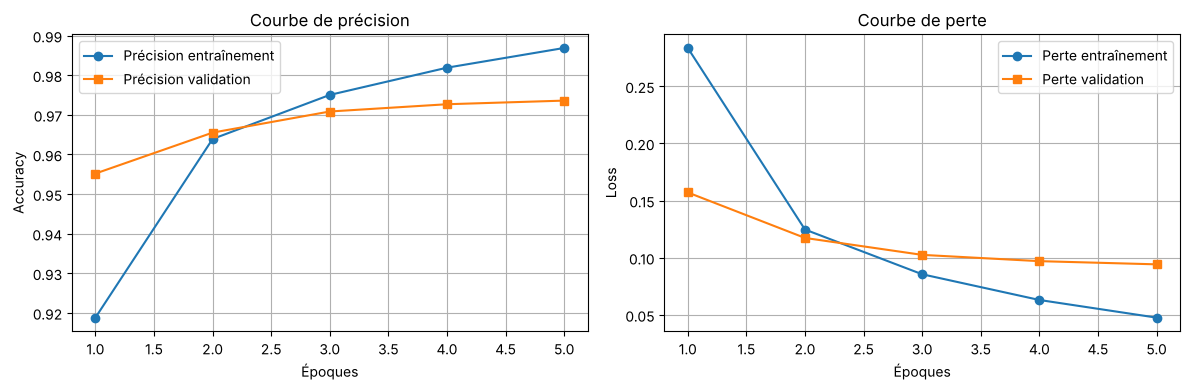

In [9]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(range(1,6), history.history['accuracy'], 'o-', label='Précision entraînement')
plt.plot(range(1,6), history.history['val_accuracy'], 's-', label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(range(1,6), history.history['loss'], 'o-', label='Perte entraînement')
plt.plot(range(1,6), history.history['val_loss'], 's-', label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Réponses

**1. Que remarquez-vous sur les deux courbes ?**
Les deux précisions montent et les deux pertes baissent : le modèle apprend. À la 1ʳᵉ époque, la validation est même **au-dessus** du train : c'est normal, car l'accuracy de train est une moyenne calculée *pendant* l'époque, avec des poids encore mauvais au début, alors que la validation est mesurée *à la fin* de l'époque. Ensuite la courbe de train passe au-dessus et l'écart se creuse : la val_loss diminue de moins en moins vite et commence à se stabiliser.

**2. Comment détecter visuellement un surapprentissage ?**
Le signe le plus fiable est sur la **courbe de perte** : la perte de train continue de baisser alors que la **perte de validation stagne puis remonte**. Les deux courbes forment alors un « V » ou une fourche. Sur la précision, c'est un écart train/validation qui se creuse alors que la validation plafonne.

**3. Stratégie pour y remédier :** **Early stopping** (on arrête à l'époque où la val_loss est minimale et on restaure les meilleurs poids), complété par du **Dropout** ou de la régularisation L2, et de la data augmentation.
```python
from tensorflow.keras.callbacks import EarlyStopping
es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
model.fit(..., epochs=50, callbacks=[es])
```

**4. Que faire si les deux courbes divergent ?**
Cela veut dire que le modèle mémorise au lieu de généraliser. Il faut :
1. revenir aux poids de l'époque où la val_loss était minimale (early stopping) ;
2. réduire la capacité du modèle ou ajouter de la régularisation (Dropout, L2) ;
3. augmenter les données ;
4. éventuellement baisser le learning rate.
Et vérifier qu'il n'y a pas un problème dans les données (validation qui ne vient pas de la même distribution que le train).

## 9. Prédictions et visualisation

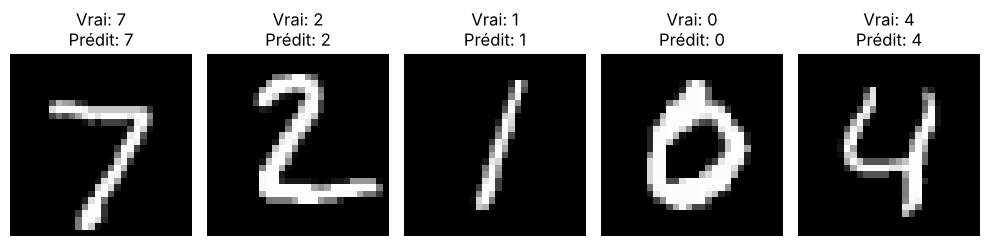

In [10]:
predictions = model.predict(x_test, verbose=0)

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Les 5 premières images sont toutes bien classées, ce qui ne dit rien sur les erreurs. Pour répondre vraiment à la question 1, on affiche les images **mal classées**, avec la confiance du modèle.

Nombre d'erreurs : 257 / 10000


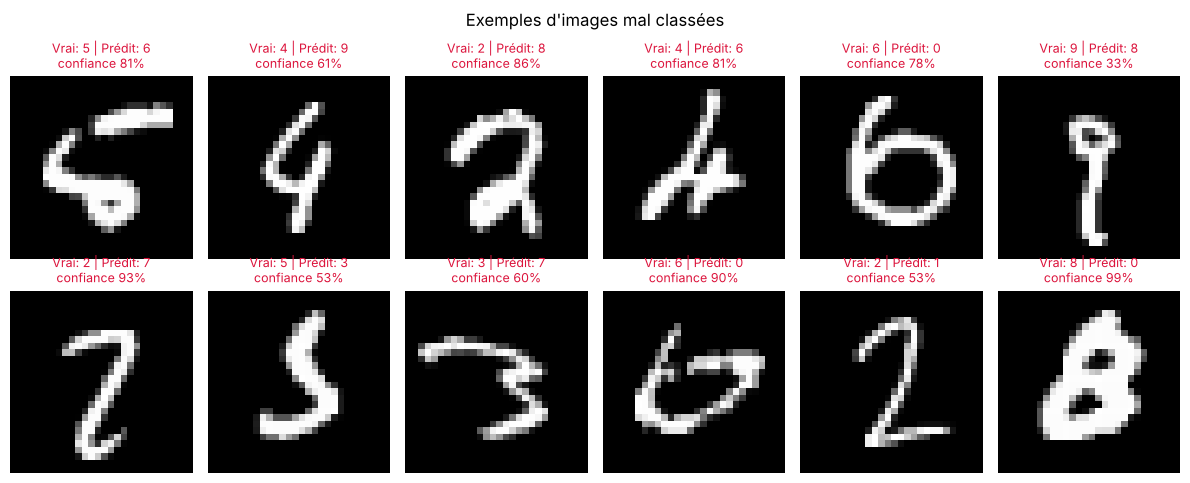

Confusions les plus fréquentes (vrai → prédit : nombre)
   3 → 5 : 12
   2 → 0 : 12
   2 → 8 : 11
   8 → 0 : 11
   4 → 9 : 10


In [11]:
y_pred = np.argmax(predictions, axis=1)
erreurs = np.where(y_pred != y_test)[0]
print(f"Nombre d'erreurs : {len(erreurs)} / {len(y_test)}")

plt.figure(figsize=(12,5))
for k, i in enumerate(erreurs[:12]):
    plt.subplot(2,6,k+1)
    plt.imshow(x_test[i], cmap='gray')
    conf = predictions[i][y_pred[i]]
    plt.title(f"Vrai: {y_test[i]} | Prédit: {y_pred[i]}\nconfiance {conf:.0%}", fontsize=9, color='crimson')
    plt.axis('off')
plt.suptitle("Exemples d'images mal classées")
plt.tight_layout()
plt.show()

# Quelles confusions reviennent le plus ?
from collections import Counter
paires = Counter(zip(y_test[erreurs], y_pred[erreurs])).most_common(5)
print("Confusions les plus fréquentes (vrai → prédit : nombre)")
for (v, p), n in paires:
    print(f"   {v} → {p} : {n}")
RES['ex1_n_err'] = int(len(erreurs))
RES['ex1_top_conf'] = [f"{v}→{p} ({n})" for (v, p), n in paires]

### Réponses

**1. Le modèle fait-il des erreurs ? Sur quelles images ?**
Oui : **257 erreurs** sur 10 000. Les confusions les plus fréquentes sont 3 → 5 (12), 2 → 0 (12), 2 → 8 (11), 8 → 0 (11). Ce sont des chiffres qui partagent des traits (un 3 dont le haut est écrasé ressemble à un 5 ; un 2 avec une boucle en bas se rapproche d'un 8 ou d'un 0 ; un 4 fermé en haut ressemble à un 9) et surtout des images **mal écrites, coupées ou très inclinées**. En regardant la grille d'erreurs, un humain hésiterait lui-même sur plusieurs d'entre elles.

**2. Comment expliquer une prédiction erronée ?**
- Le MLP **ne comprend pas la forme** : après `Flatten`, il voit 784 nombres indépendants et apprend en gros « quels pixels sont allumés pour chaque chiffre ». Un chiffre décalé de 2–3 pixels ou penché allume d'autres pixels, et le modèle se trompe même si la forme est évidente pour nous.
- Certaines images sont **ambiguës** ou mal étiquetées dans le dataset.
- Le modèle est parfois **très confiant dans son erreur** (cf. les confiances affichées) : le softmax donne une probabilité, pas une garantie.

**3. Technique pour améliorer la précision :** un **CNN** (réseau convolutif). Les filtres de convolution détectent des motifs locaux (traits, courbes, angles) **où qu'ils soient dans l'image**, et le pooling rend le modèle tolérant aux petits décalages. Un CNN simple atteint ~99 % sur MNIST contre ~97,5 % pour notre MLP, c'est-à-dire **diviser les erreurs par 2 ou 3**. On peut ajouter de la data augmentation (petites rotations/translations) et du Dropout.

## Analyse personnelle — Exercice 1

**Interprétation.** Avec seulement une couche cachée de 128 neurones et 5 époques, le modèle atteint **97,43 %** de précision sur le test. L'écart train/test est faible (0,9869 contre 0,9743), donc le modèle généralise bien et le surapprentissage reste limité à ce stade. Les erreurs restantes portent sur des chiffres qui partagent des traits (3/5, 2/0, 2/8, 4/9) ou mal écrits.

**Difficultés rencontrées.** Le code de l'énoncé utilisait le jeu de test comme validation, ce qui revient à « regarder l'examen » pendant les révisions : nous l'avons remplacé par `validation_split=0.2`. Il a aussi fallu ajouter la courbe de perte, demandée dans le rapport mais absente du code. Enfin, l'affichage des 5 premières prédictions ne montre aucune erreur : il faut chercher explicitement les images mal classées pour analyser le modèle.

**Propositions d'amélioration.**
1. Passer à un **CNN** (exercice 2) pour exploiter la structure 2D de l'image.
2. Ajouter du **Dropout** et un **EarlyStopping** pour pouvoir entraîner plus longtemps sans surapprendre.
3. Essayer une couche cachée supplémentaire ou plus de neurones, en surveillant la val_loss.
4. Ajouter de la **data augmentation** (rotations de ±10°, petites translations ; pas de symétrie horizontale, qui transformerait un 2 en un symbole qui n'existe pas).

---
# Exercice 2 — Classification d'images avec Fashion-MNIST

In [12]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pour la reproductibilité
tf.random.set_seed(42)
tf.keras.utils.set_random_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Noms des classes (dans l'ordre des labels 0 → 9)
class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

## Étape 1 — Exploration du jeu de données
### A. Dimensions et types

In [13]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type :", X_train.dtype, "| min =", X_train.min(), "| max =", X_train.max())
print("Images par classe (train) :", np.bincount(y_train))

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type : uint8 | min = 0 | max = 255
Images par classe (train) : [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


### B. Visualisation d'exemples

On ajoute le nom de la classe dans le titre : un label « 9 » seul ne dit pas qu'il s'agit d'une bottine.

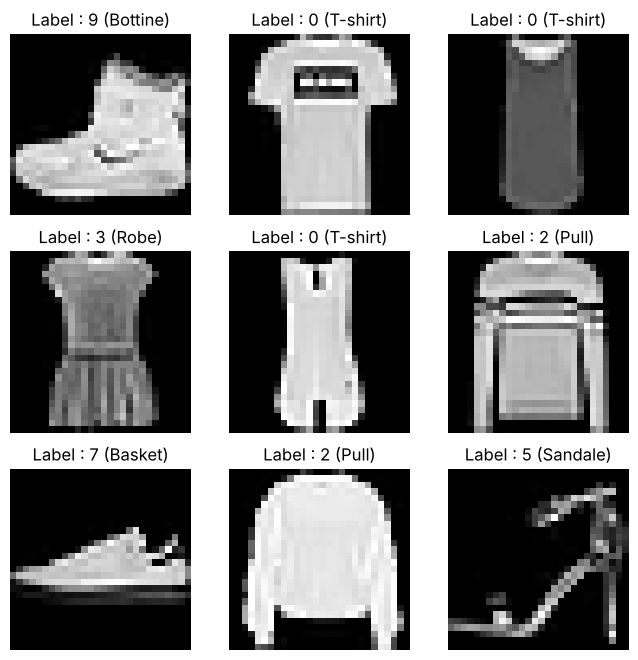

In [14]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.show()

### Question : que remarquez-vous sur la nature des données et la taille des images ?

- Le format est **identique à MNIST** : 60 000 images d'entraînement et 10 000 de test, en **28 × 28 pixels**, **niveaux de gris** (un seul canal), entiers `uint8` de 0 à 255, 10 classes **parfaitement équilibrées** (6 000 images chacune). Fashion-MNIST a justement été créé pour remplacer MNIST sans changer le code.
- Mais le problème est **plus difficile** : les vêtements ont des textures, des motifs et des formes variées, et la résolution de 28 × 28 efface beaucoup de détails (col, boutons, lacets).
- Certaines classes ont presque la **même silhouette** : T-shirt, pull, manteau et chemise sont tous des « hauts à manches ». On peut s'attendre à ce que ce soient les classes les plus confondues.
- Les objets sont **centrés et tous orientés de la même façon** (par exemple, les chaussures pointent toutes vers la gauche). C'est important pour l'étape 7.

## Étape 2 — Prétraitement des données

In [15]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Label brut :", y_train[0], "→ one-hot :", y_train_cat[0])

Label brut : 9 → one-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Réponses

**1. Pourquoi normaliser les images ?**
Pour mettre toutes les entrées sur une petite échelle commune (0–1). Les poids sont initialisés avec de petites valeurs ; avec des pixels à 255 les sommes pondérées explosent, les activations saturent et les gradients deviennent instables. Avec des entrées normalisées, l'optimiseur fait des pas cohérents et **converge plus vite**. La conversion en `float32` est nécessaire car la division d'entiers `uint8` ne donnerait pas des décimaux, et `float32` est le type natif de TensorFlow (deux fois moins de mémoire que `float64`).

**2. Importance du one-hot encoding en multiclasse :**
Le label `9` (bottine) n'est pas « plus grand » que le label `5` (sandale) : les numéros de classe sont **nominaux**, pas ordonnés. Le one-hot transforme chaque label en vecteur de 10 cases avec un 1 à la position de la classe (`9 → [0,0,0,0,0,0,0,0,0,1]`). Ça a deux intérêts :
- la cible a **la même forme que la sortie softmax** (10 probabilités), donc la `categorical_crossentropy` peut comparer les deux case par case ;
- on évite toute notion d'ordre ou de distance artificielle entre classes.

*Remarque :* on pourrait garder les labels entiers et utiliser `sparse_categorical_crossentropy` (comme dans l'exercice 1). Le résultat est mathématiquement identique ; `sparse` évite juste de construire les vecteurs one-hot.

## Étape 3 — Création d'un modèle dense (ANN)
### Création du modèle de base

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 784 × 128 + 128 = 100 480, puis 128 × 64 + 64 = 8 256, puis 64 × 10 + 10 = 650, soit **109 386** au total. Le `Dropout(0.2)` n'a pas de paramètre : à chaque batch, il met à zéro 20 % des sorties de la couche précédente, au hasard (uniquement pendant l'entraînement).

### Compilation et entraînement

In [17]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=2
)

Epoch 1/10


375/375 - 2s - 6ms/step - accuracy: 0.7817 - loss: 0.6212 - val_accuracy: 0.8436 - val_loss: 0.4327


Epoch 2/10


375/375 - 1s - 4ms/step - accuracy: 0.8476 - loss: 0.4249 - val_accuracy: 0.8540 - val_loss: 0.3989


Epoch 3/10


...

375/375 - 1s - 4ms/step - accuracy: 0.8868 - loss: 0.3048 - val_accuracy: 0.8729 - val_loss: 0.3459


Epoch 9/10


375/375 - 1s - 3ms/step - accuracy: 0.8891 - loss: 0.2984 - val_accuracy: 0.8719 - val_loss: 0.3489


Epoch 10/10


375/375 - 1s - 4ms/step - accuracy: 0.8927 - loss: 0.2887 - val_accuracy: 0.8785 - val_loss: 0.3363


### Visualisation

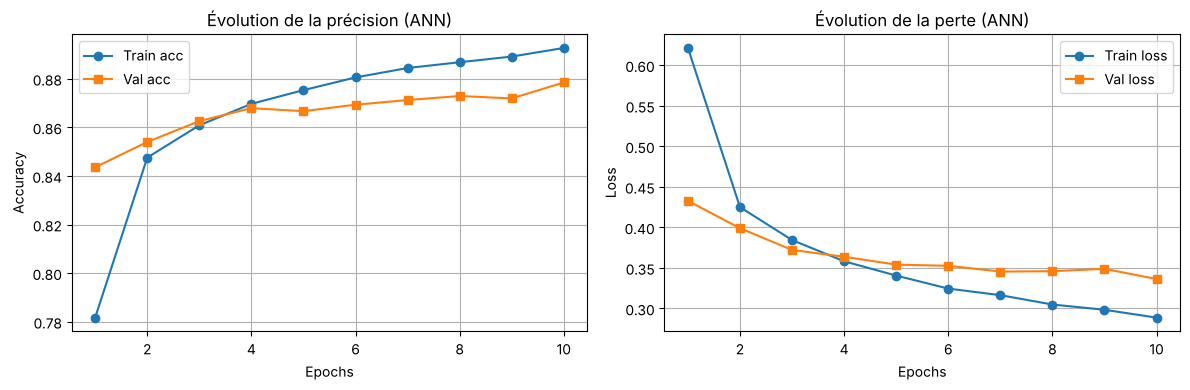

In [18]:
def plot_history(history, titre):
    h = history.history
    ep = range(1, len(h['accuracy']) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, h['accuracy'], 'o-', label='Train acc')
    plt.plot(ep, h['val_accuracy'], 's-', label='Val acc')
    plt.legend(); plt.grid(True)
    plt.title(f'Évolution de la précision ({titre})')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(ep, h['loss'], 'o-', label='Train loss')
    plt.plot(ep, h['val_loss'], 's-', label='Val loss')
    plt.legend(); plt.grid(True)
    plt.title(f'Évolution de la perte ({titre})')
    plt.xlabel('Epochs'); plt.ylabel('Loss')
    plt.tight_layout()
    plt.show()

plot_history(history, 'ANN')

### Évaluation finale

In [19]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print("Précision sur le test set :", round(test_acc, 4))
RES['ann_train_acc'] = history.history['accuracy'][-1]
RES['ann_val_acc'] = history.history['val_accuracy'][-1]
RES['ann_test_acc'] = test_acc

Précision sur le test set : 0.8715


### Réponses

**1. Pourquoi utilise-t-on ReLU ici ?**
- **Pas de saturation pour les valeurs positives** : sa dérivée vaut 1 dès que $x > 0$, donc le gradient traverse les couches sans être écrasé (contrairement à sigmoïde/tanh, cf. étape 4).
- **Calcul très simple** : un simple $\max(0, x)$, sans exponentielle, donc rapide.
- **Activations creuses** : les neurones à valeur négative sortent 0, seuls certains neurones « s'allument » pour un motif donné, ce qui aide à spécialiser les neurones.
Sans aucune activation non linéaire, empiler des couches `Dense` reviendrait à un seul modèle linéaire ; ReLU apporte la non-linéarité au coût le plus faible.

**2. Différence entre `accuracy` et `val_accuracy` :**
`accuracy` est mesurée sur les **48 000 images d'entraînement** (et calculée en cours d'époque, pendant que les poids changent, avec le Dropout actif). `val_accuracy` est mesurée en fin d'époque sur les **12 000 images de validation**, jamais utilisées pour mettre à jour les poids, et sans Dropout. La première dit « le modèle a-t-il appris le train ? », la seconde « est-ce qu'il généralise ? ». Ici : 0,8927 contre 0,8785 à la 10ᵉ époque.

**3. Que se passe-t-il avec 50 époques ?**
La précision de train continuerait de monter (vers 95 %+), mais la validation plafonnerait autour de 89–90 % et la **val_loss remonterait** à partir d'une quinzaine d'époques : surapprentissage. Le Dropout(0.2) retarde le phénomène mais ne l'empêche pas. Il faudrait un `EarlyStopping` pour s'arrêter au bon moment.

**Résultat :** l'ANN obtient **87,15 %** sur le test, nettement moins que les ~97,5 % de MNIST avec un réseau comparable : Fashion-MNIST est bien plus difficile.

## Étape 4 — Introduction aux fonctions d'activation

**Objectif :** comparer sigmoïde, tanh, ReLU et LeakyReLU, avec la même architecture (128 → 64 → 10), 5 époques chacune.

sigmoid    → val_accuracy = 0.8623 | 1ʳᵉ époque : 0.8174


tanh       → val_accuracy = 0.8707 | 1ʳᵉ époque : 0.8545


relu       → val_accuracy = 0.8664 | 1ʳᵉ époque : 0.8472


LeakyReLU  → val_accuracy = 0.8687 | 1ʳᵉ époque : 0.8482


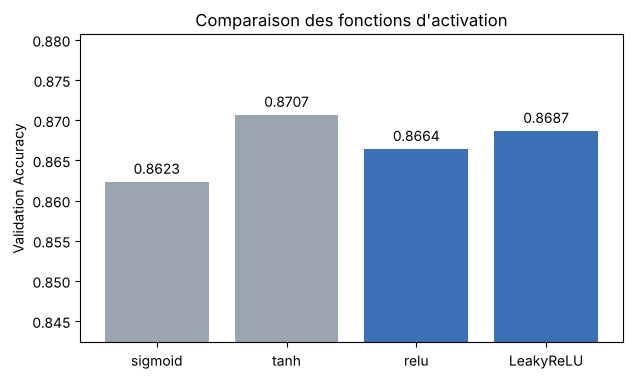

In [20]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    tf.keras.utils.set_random_seed(42)   # même initialisation pour une comparaison équitable
    model_act = Sequential([
        Input(shape=(28,28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]
    print(f"{act:10s} → val_accuracy = {results[act]:.4f} | 1ʳᵉ époque : {h.history['val_accuracy'][0]:.4f}")

# Leaky ReLU
tf.keras.utils.set_random_seed(42)
model_leaky = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]
print(f"{'LeakyReLU':10s} → val_accuracy = {results['LeakyReLU']:.4f} | 1ʳᵉ époque : {h.history['val_accuracy'][0]:.4f}")

plt.figure(figsize=(7,4))
bars = plt.bar(results.keys(), results.values(), color=['#9aa5b1', '#9aa5b1', '#3b6fb6', '#3b6fb6'])
for b, v in zip(bars, results.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 0.001, f"{v:.4f}", ha='center', fontsize=10)
plt.ylim(min(results.values()) - 0.02, max(results.values()) + 0.01)   # zoom : sinon les barres paraissent identiques
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()
RES['activations'] = {k: float(v) for k, v in results.items()}

> Attention à l'axe vertical : il est **zoomé** (il ne commence pas à 0). Sans zoom, les 4 barres auraient l'air identiques ; avec le zoom, les écarts paraissent plus grands qu'ils ne le sont. Il faut lire les valeurs, pas la hauteur des barres.

### Réponses

**1. Quelle fonction donne les meilleurs résultats ?**
Classement obtenu : **tanh** (0,8707) > **LeakyReLU** (0,8687) > **relu** (0,8664) > **sigmoid** (0,8623). Les écarts sont **faibles** (de l'ordre de 0,8 point entre la meilleure et la moins bonne). Avec 5 époques et une seule exécution, une partie de cet écart vient du hasard (initialisation, ordre des batchs) : il faudrait répéter l'expérience avec plusieurs graines pour conclure de façon rigoureuse. Ce qui est net, c'est que **sigmoïde est la dernière** et surtout qu'elle **démarre le plus lentement** (0,817 de val_accuracy après la 1ʳᵉ époque, contre ~0,85 pour les trois autres) : c'est l'effet de ses petits gradients. Que tanh finisse légèrement devant ReLU n'est pas surprenant ici : avec seulement 2 couches cachées, le gradient n'a pas le temps de « disparaître », donc l'avantage principal de ReLU ne joue presque pas. Sur un réseau profond (10, 20, 50 couches), la famille ReLU prend nettement le dessus, c'est pour ça qu'elle est le choix par défaut.

**2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
- **Saturation et disparition du gradient (vanishing gradient)** : pour $|x|$ grand, les deux courbes deviennent plates, donc leur dérivée est presque nulle. La dérivée de la sigmoïde vaut **au maximum 0,25** ; en rétropropagation on multiplie ces dérivées couche après couche, donc avec 10 couches le gradient est multiplié par au plus $0{,}25^{10} \approx 10^{-6}$ : les premières couches n'apprennent presque plus.
- **Sigmoïde non centrée en 0** (sorties entre 0 et 1, toujours positives) : les mises à jour des poids d'un même neurone ont toutes le même signe, ce qui fait zigzaguer la descente de gradient. Tanh (sorties entre −1 et 1) corrige ce point, c'est pour ça qu'elle fait généralement mieux que sigmoïde, mais elle sature toujours.
- **Exponentielle plus coûteuse** à calculer que $\max(0,x)$.
Elles restent utiles **en sortie** (sigmoïde pour une classification binaire) et dans les portes des LSTM/GRU.

**3. À quoi sert LeakyReLU ?**
ReLU donne 0 **et une dérivée nulle** pour toute entrée négative. Si un neurone reçoit des entrées négatives pour toutes les images (par exemple après une grosse mise à jour), il ne reçoit plus jamais de gradient et ne réapprend plus : c'est le problème des **« neurones morts » (dying ReLU)**. LeakyReLU laisse passer une petite pente pour les valeurs négatives : $f(x) = x$ si $x>0$, sinon $0{,}1 \cdot x$ ici. Le gradient n'est donc jamais exactement nul et le neurone peut toujours « se réveiller ».

## Étape 5 — Modèle CNN (Convolutional Neural Network)
### Création du modèle CNN

Les étudiants créent un réseau de neurones convolutif pour exploiter la structure spatiale des images. On l'écrit dans une fonction `build_cnn()` pour pouvoir **recréer un CNN neuf** à l'étape 7.

In [21]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal"
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

def build_cnn():
    cnn = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, (3,3), activation='relu'),
        MaxPooling2D((2,2)),
        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D((2,2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(10, activation='softmax')
    ])
    cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return cnn

tf.keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

**Lecture du `summary()` :**

| Couche | Forme de sortie | Paramètres | Calcul |
|---|---|---|---|
| Conv2D(32, 3×3) | 26 × 26 × 32 | 320 | 32 filtres × (3×3×1 poids + 1 biais) |
| MaxPooling2D | 13 × 13 × 32 | 0 | on garde le max de chaque carré 2×2 |
| Conv2D(64, 3×3) | 11 × 11 × 64 | 18 496 | 64 × (3×3×**32** + 1) : chaque filtre regarde les 32 cartes |
| MaxPooling2D | 5 × 5 × 64 | 0 | 11 ÷ 2 = 5 (arrondi inférieur) |
| Flatten | 1 600 | 0 | 5 × 5 × 64 |
| Dense(128) | 128 | 204 928 | 1 600 × 128 + 128 |
| Dropout(0.3) | 128 | 0 | |
| Dense(10) | 10 | 1 290 | |
| **Total** | | **225 034** | |

Pourquoi 26 et non 28 ? Un filtre 3×3 sans padding ne peut pas se centrer sur les pixels du bord : on perd 1 pixel de chaque côté, donc 28 − 2 = 26.

Les deux couches de convolution ne représentent que **~8 %** des paramètres : un filtre 3×3 n'a que 9 poids (× nombre de canaux) et **le même filtre est réutilisé à toutes les positions** de l'image (partage des poids).

### Entraînement

In [22]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=2
)

Epoch 1/10


375/375 - 9s - 25ms/step - accuracy: 0.7720 - loss: 0.6312 - val_accuracy: 0.8561 - val_loss: 0.4052


Epoch 2/10


375/375 - 10s - 27ms/step - accuracy: 0.8591 - loss: 0.3920 - val_accuracy: 0.8771 - val_loss: 0.3430


Epoch 3/10


...

375/375 - 9s - 24ms/step - accuracy: 0.9131 - loss: 0.2384 - val_accuracy: 0.9052 - val_loss: 0.2575


Epoch 9/10


375/375 - 8s - 22ms/step - accuracy: 0.9174 - loss: 0.2218 - val_accuracy: 0.9093 - val_loss: 0.2490


Epoch 10/10


375/375 - 9s - 24ms/step - accuracy: 0.9226 - loss: 0.2112 - val_accuracy: 0.9090 - val_loss: 0.2482


### Évaluation

Précision CNN sur test set : 0.9032


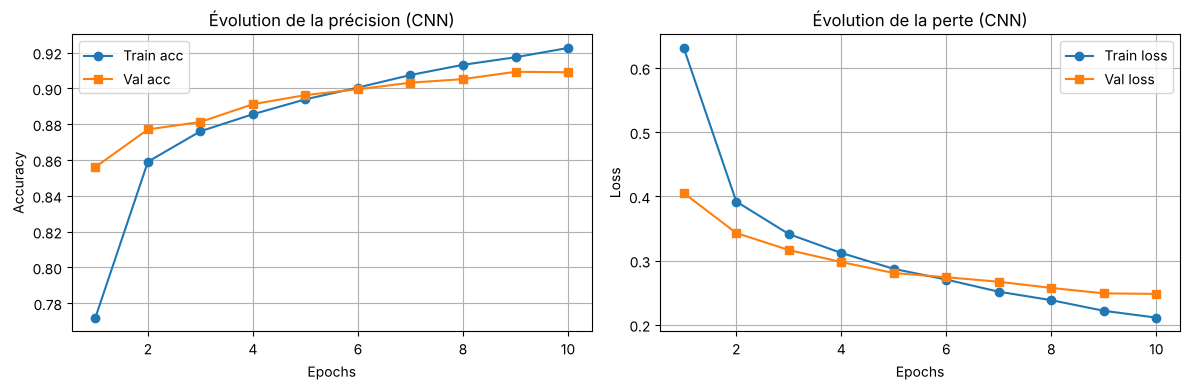

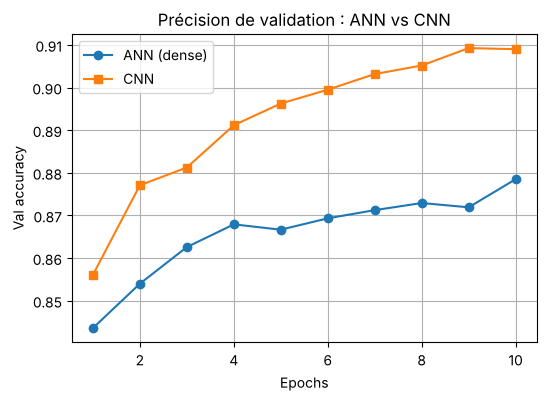

In [23]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)
print("Précision CNN sur test set :", round(test_acc, 4))
RES['cnn_train_acc'] = history_cnn.history['accuracy'][-1]
RES['cnn_val_acc'] = history_cnn.history['val_accuracy'][-1]
RES['cnn_test_acc'] = test_acc

plot_history(history_cnn, 'CNN')

# Comparaison directe ANN vs CNN sur la validation
plt.figure(figsize=(6,4))
plt.plot(range(1,11), history.history['val_accuracy'], 'o-', label='ANN (dense)')
plt.plot(range(1,11), history_cnn.history['val_accuracy'], 's-', label='CNN')
plt.title('Précision de validation : ANN vs CNN')
plt.xlabel('Epochs'); plt.ylabel('Val accuracy'); plt.grid(True); plt.legend()
plt.show()

### Réponses

**Résultat :** le CNN atteint **90,32 %** sur le test contre **87,15 %** pour l'ANN. Le taux d'erreur passe de 12,8 % à 9,7 %, soit **~25 % d'erreurs en moins**, avec seulement 2 fois plus de paramètres.

**1. Différence entre un ANN et un CNN :**

| | ANN (dense) | CNN |
|---|---|---|
| Entrée | vecteur de 784 pixels (`Flatten` dès le départ) | image 28×28×1 qui garde sa forme 2D |
| Connexions | chaque neurone voit **tous** les pixels | chaque filtre ne voit qu'un **petit voisinage** (3×3) |
| Poids | un poids différent pour chaque pixel | le **même filtre glisse** sur toute l'image (partage des poids) |
| Ce qu'il apprend | « quels pixels sont allumés » à des positions fixes | des **motifs locaux** (bords, coins, textures), puis des motifs de plus en plus complexes |
| Sensibilité au décalage | forte : un objet décalé de 2 px = autres pixels | faible : le filtre détecte le motif où qu'il soit, et le pooling absorbe les petits décalages |

**2. Pourquoi le CNN donne-t-il de meilleurs résultats ?**
- **Il exploite la structure spatiale** : dans une image, un pixel a du sens avec ses voisins. Le CNN regarde des petits blocs, ce qui correspond à la nature des données.
- **Hiérarchie de caractéristiques** : la 1ʳᵉ convolution détecte des bords et des contrastes, la 2ᵉ combine ces bords en formes (col, manche, semelle, anse de sac). La couche dense finale décide à partir de ces formes, pas de pixels bruts.
- **Partage des poids** : un détecteur de « bord vertical » appris en haut de l'image sert aussi en bas. Le modèle a besoin de beaucoup moins de paramètres pour extraire ces caractéristiques, et il généralise mieux.
*Analogie :* l'ANN lit une photo comme une liste de 784 nombres ; le CNN la regarde comme nous, en repérant des contours puis des formes.

**3. Rôle des couches de Pooling :**
Le `MaxPooling2D((2,2))` découpe chaque carte en carrés de 2×2 et garde **la valeur maximale** de chaque carré.
- **Réduit la taille** des cartes par 2 dans chaque direction (26×26 → 13×13), donc 4 fois moins de valeurs : moins de calculs et moins de paramètres dans la couche dense qui suit.
- **Apporte une invariance aux petits décalages** : si le motif bouge d'un pixel dans le carré 2×2, le max reste le même.
- **Garde l'information la plus forte** : « ce motif est-il présent dans cette zone ? » plutôt que sa position exacte au pixel près.
- Agrandit le champ de vision des couches suivantes : après un pooling, un filtre 3×3 couvre une zone de 6×6 pixels de l'image d'origine.

## Étape 6 — Visualisation des performances

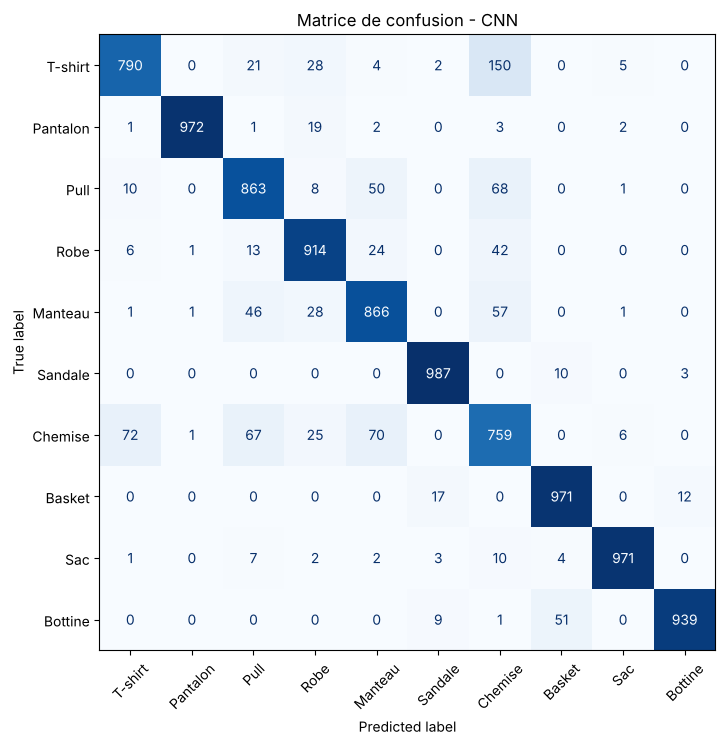

Confusions les plus fréquentes (vrai → prédit : nombre d'images)
   T-shirt   → Chemise   : 150
   Chemise   → T-shirt   : 72
   Chemise   → Manteau   : 70
   Pull      → Chemise   : 68
   Chemise   → Pull      : 67
   Manteau   → Chemise   : 57

Taux de bonne classification par classe :
   Chemise   : 75.9%
   T-shirt   : 79.0%
   Pull      : 86.3%
   Manteau   : 86.6%
   Robe      : 91.4%
   Bottine   : 93.9%
   Basket    : 97.1%
   Sac       : 97.1%
   Pantalon  : 97.2%
   Sandale   : 98.7%


In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(cnn.predict(X_test_cnn, verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names,
                                        cmap="Blues", xticks_rotation=45, ax=ax, colorbar=False)
plt.title("Matrice de confusion - CNN")
plt.show()

# Confusions les plus fréquentes (hors diagonale)
cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)
idx = np.dstack(np.unravel_index(np.argsort(-cm.ravel()), cm.shape))[0][:6]
print("Confusions les plus fréquentes (vrai → prédit : nombre d'images)")
top = []
for v, p in idx:
    print(f"   {class_names[v]:9s} → {class_names[p]:9s} : {cm[v, p]}")
    top.append(f"{class_names[v]} → {class_names[p]} ({cm[v, p]})")

# Précision par classe
cm_full = confusion_matrix(y_test, y_pred)
rappel = cm_full.diagonal() / cm_full.sum(axis=1)
print("\nTaux de bonne classification par classe :")
for c, r in sorted(zip(class_names, rappel), key=lambda t: t[1]):
    print(f"   {c:9s} : {r:.1%}")
RES['cnn_top_conf'] = top
RES['cnn_class_rates'] = {c: float(r) for c, r in zip(class_names, rappel)}

### Réponses

**1. Quelles classes sont le plus souvent confondues ?**
Les confusions principales sont : **T-shirt → Chemise (150)**, **Chemise → T-shirt (72)**, **Chemise → Manteau (70)**, **Pull → Chemise (68)**, **Chemise → Pull (67)**.
La classe la plus difficile est de loin **Chemise** (75,9 % bien classées seulement), alors que Sandale, Pantalon, Sac et Basket dépassent 97 %. Toutes les grosses confusions se passent **à l'intérieur du groupe des hauts** (T-shirt, Pull, Manteau, Chemise) : en 28×28 niveaux de gris, ils ont la même silhouette, et ce qui les distingue (col, boutons, longueur des manches, matière) disparaît presque à cette résolution. L'autre groupe confondu, mais beaucoup moins, est celui des **chaussures** (Basket ↔ Sandale ↔ Bottine).

**2. Comment réduire ces erreurs ?**
- **Un modèle plus puissant** : une 3ᵉ couche de convolution, plus de filtres, du `padding='same'` pour ne pas perdre les bords, et de la `BatchNormalization`. Les CNN plus profonds atteignent ~93–94 % sur ce dataset.
- **Entraîner plus longtemps** avec `EarlyStopping` et un learning rate décroissant (`ReduceLROnPlateau`).
- **Data augmentation adaptée** (étape 7) pour rendre le modèle robuste aux variations.
- **Pondérer les classes difficiles** (`class_weight` pour Chemise) ou ajouter des exemples de ces classes.
- **Transfer learning** depuis un modèle pré-entraîné, ou des images en **plus haute résolution** (c'est la limite fondamentale : à 28×28, même un humain hésite entre une chemise et un T-shirt).

## Étape 7 — Data Augmentation

> **Modifications par rapport à l'énoncé :**
> 1. Le code d'origine appelle `cnn.fit(...)` sur le CNN **déjà entraîné** à l'étape 5 : le modèle cumulerait alors 20 époques, et on ne pourrait pas savoir si un gain vient de l'augmentation ou des 10 époques supplémentaires. On entraîne donc un **CNN neuf** (`build_cnn()`) pendant 10 époques, dans les mêmes conditions que le CNN de l'étape 5.
> 2. Comme ailleurs, la validation se fait sur les 20 % de fin du train (exactement les mêmes images que `validation_split=0.2`), et pas sur le test.
> 3. `ImageDataGenerator` est **déprécié** dans les versions récentes de Keras (il fonctionne encore, avec un avertissement). L'alternative moderne est d'ajouter des couches `RandomFlip`, `RandomRotation`, `RandomZoom` au début du modèle.

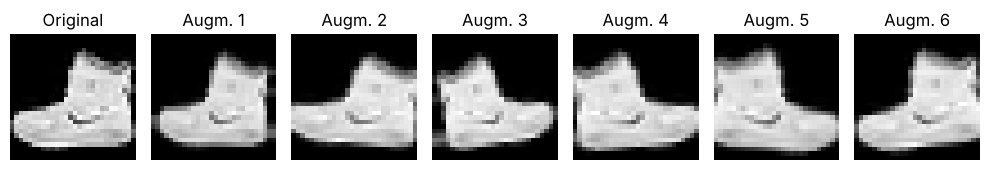

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Même découpage que validation_split=0.2 (Keras prend les 20 % de fin)
n_val = int(0.2 * len(X_train_cnn))
X_tr, X_val = X_train_cnn[:-n_val], X_train_cnn[-n_val:]
y_tr, y_val = y_train_cat[:-n_val], y_train_cat[-n_val:]

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_tr)

# Aperçu : une même image transformée plusieurs fois
plt.figure(figsize=(10, 2.3))
batch = next(datagen.flow(np.repeat(X_tr[:1], 6, axis=0), batch_size=6, shuffle=False))
plt.subplot(1, 7, 1); plt.imshow(X_tr[0].squeeze(), cmap='gray'); plt.title('Original'); plt.axis('off')
for k in range(6):
    plt.subplot(1, 7, k + 2); plt.imshow(batch[k].squeeze(), cmap='gray'); plt.title(f'Augm. {k+1}'); plt.axis('off')
plt.tight_layout(); plt.show()

In [26]:
tf.keras.utils.set_random_seed(42)
cnn_aug = build_cnn()      # CNN neuf, mêmes poids initiaux que celui de l'étape 5

history_aug = cnn_aug.fit(
    datagen.flow(X_tr, y_tr, batch_size=128),
    epochs=10,
    validation_data=(X_val, y_val),
    verbose=2
)

test_loss_aug, test_acc_aug = cnn_aug.evaluate(X_test_cnn, y_test_cat, verbose=0)
print("Précision CNN + data augmentation sur test set :", round(test_acc_aug, 4))
RES['aug_train_acc'] = history_aug.history['accuracy'][-1]
RES['aug_val_acc'] = history_aug.history['val_accuracy'][-1]
RES['aug_test_acc'] = test_acc_aug

Epoch 1/10


375/375 - 14s - 36ms/step - accuracy: 0.7275 - loss: 0.7518 - val_accuracy: 0.8282 - val_loss: 0.4686


Epoch 2/10


375/375 - 20s - 54ms/step - accuracy: 0.8166 - loss: 0.4954 - val_accuracy: 0.8628 - val_loss: 0.3781


Epoch 3/10


...

Epoch 9/10


375/375 - 13s - 34ms/step - accuracy: 0.8784 - loss: 0.3290 - val_accuracy: 0.8972 - val_loss: 0.2835


Epoch 10/10


375/375 - 13s - 35ms/step - accuracy: 0.8834 - loss: 0.3173 - val_accuracy: 0.8970 - val_loss: 0.2840


Précision CNN + data augmentation sur test set : 0.8924


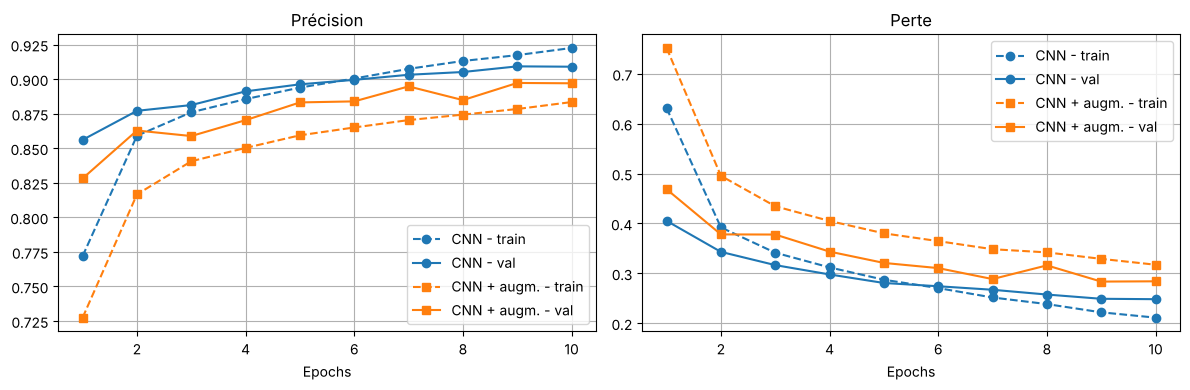

Écart train - val à la 10e époque : CNN = +0.0136 | CNN + augmentation = -0.0136


In [27]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1,11), history_cnn.history['accuracy'], 'o--', color='tab:blue', label='CNN - train')
plt.plot(range(1,11), history_cnn.history['val_accuracy'], 'o-', color='tab:blue', label='CNN - val')
plt.plot(range(1,11), history_aug.history['accuracy'], 's--', color='tab:orange', label='CNN + augm. - train')
plt.plot(range(1,11), history_aug.history['val_accuracy'], 's-', color='tab:orange', label='CNN + augm. - val')
plt.title('Précision'); plt.xlabel('Epochs'); plt.grid(True); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(range(1,11), history_cnn.history['loss'], 'o--', color='tab:blue', label='CNN - train')
plt.plot(range(1,11), history_cnn.history['val_loss'], 'o-', color='tab:blue', label='CNN - val')
plt.plot(range(1,11), history_aug.history['loss'], 's--', color='tab:orange', label='CNN + augm. - train')
plt.plot(range(1,11), history_aug.history['val_loss'], 's-', color='tab:orange', label='CNN + augm. - val')
plt.title('Perte'); plt.xlabel('Epochs'); plt.grid(True); plt.legend()
plt.tight_layout(); plt.show()

gap_cnn = history_cnn.history['accuracy'][-1] - history_cnn.history['val_accuracy'][-1]
gap_aug = history_aug.history['accuracy'][-1] - history_aug.history['val_accuracy'][-1]
print(f"Écart train - val à la 10e époque : CNN = {gap_cnn:+.4f} | CNN + augmentation = {gap_aug:+.4f}")
RES['gap_cnn'] = gap_cnn
RES['gap_aug'] = gap_aug

### Réponses

**Résultat :** CNN sans augmentation **90,32 %**, CNN avec augmentation **89,24 %** sur le test. Écart train − validation à la 10ᵉ époque : +1,36 point sans augmentation, -1,36 point avec.


**Interprétation :** avec l'augmentation, le modèle fait **un peu moins bien** sur le test (−1,1 point), mais sa précision de validation est **au-dessus** de sa précision de train à la fin, alors que c'était l'inverse sans augmentation. Ça veut dire que le modèle augmenté **ne surapprend pas du tout** : il est même en sous-apprentissage. Les images transformées rendent la tâche plus difficile, et 10 époques ne suffisent pas pour qu'il converge (sa précision de train progresse encore à chaque époque). Le CNN sans augmentation, lui, n'avait pas encore beaucoup surappris au bout de 10 époques ; il y avait donc peu à gagner. Le bénéfice de l'augmentation apparaîtrait sur un entraînement plus long (30–50 époques), quand le CNN simple commence à surapprendre. Enfin, `horizontal_flip` n'est pas idéal pour ce dataset (voir question 2).

**1. Intérêt de la Data Augmentation :**
On crée, à chaque époque, des **versions légèrement modifiées** des images d'entraînement (tournées, zoomées, retournées). Le modèle ne voit jamais deux fois exactement la même image, il ne peut donc pas les mémoriser : il est forcé d'apprendre ce qui ne change pas (la forme d'une bottine) plutôt que des détails au pixel près. C'est une **régularisation** qui réduit le surapprentissage, sans collecter de nouvelles données, et qui rend le modèle robuste aux variations qu'il rencontrera en conditions réelles (photo un peu penchée, objet plus ou moins grand).
Le prix à payer : l'entraînement est plus lent (les images sont transformées à la volée) et il faut **plus d'époques** pour converger, car la tâche est plus difficile. Sur 10 époques seulement, le gain peut être nul ou même légèrement négatif ; il apparaît sur des entraînements plus longs, quand le modèle sans augmentation commence à surapprendre.

**2. Transformations les plus efficaces pour ce dataset :**
La règle : une transformation est utile seulement si elle produit une image **qu'on pourrait réellement rencontrer dans le test**.
- **Petits décalages** (`width_shift_range=0.1`, `height_shift_range=0.1`) et **petit zoom** (`zoom_range=0.1`) : les plus pertinents, car la taille et le cadrage des vêtements varient légèrement.
- **Petites rotations** (±10°) : utiles, sans exagérer (un pantalon tourné de 90° n'existe pas dans le dataset).
- **`horizontal_flip`** : bon pour les hauts, pantalons, robes et sacs, qui sont à peu près symétriques. Mais dans Fashion-MNIST, **toutes les chaussures pointent vers la gauche** (vérifié : 93 % des sandales, 99,7 % des baskets et 100 % des bottines sont orientées comme l'image moyenne de leur classe, contre 73 % pour les T-shirts, qui sont symétriques) : le retournement crée des sandales/baskets/bottines tournées vers la droite, qui n'existent jamais dans le test. Le modèle gaspille de la capacité à apprendre ces cas, ce qui peut expliquer une partie de la baisse sur ces classes.
- **À éviter** : `vertical_flip` (un T-shirt à l'envers n'existe pas), les grandes rotations, et les modifications de couleur (images en niveaux de gris).
Pour aider la classe **Chemise**, l'augmentation ne suffit pas : le problème est la résolution trop faible, pas un manque de variété.

## Récapitulatif des résultats

In [28]:
import pandas as pd
recap = pd.DataFrame({
    'Modèle': ['Ex1 - MLP (MNIST)', 'Ex2 - ANN dense', 'Ex2 - CNN', 'Ex2 - CNN + data augmentation'],
    'Paramètres': [101_770, 109_386, 225_034, 225_034],
    'Époques': [5, 10, 10, 10],
    'Acc. train': [RES['ex1_train_acc'], RES['ann_train_acc'], RES['cnn_train_acc'], RES['aug_train_acc']],
    'Acc. validation': [RES['ex1_val_acc'], RES['ann_val_acc'], RES['cnn_val_acc'], RES['aug_val_acc']],
    'Acc. test': [RES['ex1_test_acc'], RES['ann_test_acc'], RES['cnn_test_acc'], RES['aug_test_acc']],
})
display(recap.style.format({'Acc. train': '{:.2%}', 'Acc. validation': '{:.2%}', 'Acc. test': '{:.2%}', 'Paramètres': '{:,}'}).hide(axis='index'))

with open('resultats_tp2.json', 'w') as f:
    json.dump({k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in RES.items()}, f, indent=2, ensure_ascii=False)

Modèle,Paramètres,Époques,Acc. train,Acc. validation,Acc. test
Ex1 - MLP (MNIST),"101,770",5,98.69%,97.36%,97.43%
Ex2 - ANN dense,"109,386",10,89.27%,87.85%,87.15%
Ex2 - CNN,"225,034",10,92.26%,90.90%,90.32%
Ex2 - CNN + data augmentation,"225,034",10,88.34%,89.70%,89.24%


## Analyse personnelle — Exercice 2

**Interprétation.** Sur Fashion-MNIST, le réseau dense plafonne à **87,15 %**, alors qu'un réseau de même taille dépassait 97 % sur MNIST : le dataset est beaucoup plus difficile, car plusieurs classes partagent la même silhouette. Le **CNN** monte à **90,32 %** et réduit les erreurs de ~25 %, parce que les convolutions détectent des motifs locaux (bords, textures, formes) au lieu de pixels isolés. La comparaison des activations montre des écarts faibles (moins d'un point) sur un réseau aussi peu profond : tanh finit légèrement devant et sigmoïde derrière, avec un démarrage plus lent ; ReLU reste le choix par défaut pour les réseaux profonds car elle ne sature pas. La matrice de confusion montre que l'essentiel des erreurs restantes se trouve dans le groupe des hauts, avec la classe **Chemise** comme point faible (75,9 %). La data augmentation n'a pas amélioré le score en 10 époques (89,24 % contre 90,32 %) : elle a supprimé l'écart train/validation, mais le modèle n'a pas eu le temps de converger sur des images plus variées, et le retournement horizontal crée des chaussures orientées dans un sens absent du test.

**Difficultés rencontrées.** Plusieurs points du code de l'énoncé auraient faussé les comparaisons : à l'étape 7, ré-entraîner le CNN déjà entraîné aurait mélangé l'effet de l'augmentation avec celui de 10 époques supplémentaires (nous avons repris un modèle neuf) ; le graphique en barres des activations, sans valeurs ni axe adapté, ne permet pas de lire des écarts de quelques dixièmes de point ; enfin, une seule exécution de 5 époques ne permet pas de conclure statistiquement entre des activations aussi proches. `ImageDataGenerator` est aussi déprécié et produit un avertissement.

**Propositions d'amélioration.**
1. **Architecture** : un bloc de convolution supplémentaire, `padding='same'`, `BatchNormalization` après chaque convolution.
2. **Entraînement** : plus d'époques avec `EarlyStopping` et `ReduceLROnPlateau`, et répéter chaque expérience avec plusieurs graines pour obtenir une moyenne et un écart-type.
3. **Augmentation adaptée** : remplacer le retournement horizontal par de petites translations, ou le désactiver pour les chaussures, et utiliser les couches `RandomFlip` / `RandomRotation` / `RandomZoom` de Keras.
4. **Hyperparamètres** : tester le nombre de filtres, le taux de Dropout et la taille de batch avec une recherche systématique (KerasTuner).